# Milestone 3 — Improving the U-Net with a pretrained residual encoder

**Milestone 3 rules:** no changes to hyper-parameters, loss function or metrics, no different model, no data augmentation.

**Improvement:** keep the U-Net (same decoder blocks, skip connections, transposed-conv upsampling and 1×1 head)
but upgrade its encoder from plain conv blocks to **ResNet-34 residual stages initialised from ImageNet** (transfer learning).

| Run | Model | Encoder init | Role |
|---|---|---|---|
| `A_baseline` | U-Net (Milestone 2) | random | baseline, reloaded from `outputs/` (not retrained) |
| `D_resunet_scratch` | U-Net + ResNet-34 encoder | random | ablation: architecture change only |
| `E_resunet_imagenet` | U-Net + ResNet-34 encoder | ImageNet | **the improvement** |

Everything else is identical to Milestone 2: data split, preprocessing (resize only, no augmentation), cross-entropy loss,
AdamW, learning rate, batch size, epochs, seed, metrics. `D` vs `E` isolates the effect of pretraining; `A` vs `D` the effect of the architecture.

> Kernel: select a **Python** kernel on the Colab GPU runtime. Colab already has torch/torchvision, so no install cell is needed.

In [ ]:
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from torchvision import tv_tensors
from torchvision.models import resnet34, ResNet34_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # fixed input size -> faster convs
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.14.1+cu130 | device: cuda


In [ ]:
# ---- experimental setup: IDENTICAL to Milestone 2 (must stay equal so the baseline is reloaded, not retrained) ----
CFG = dict(
    img_size=256,        # images bilinear, masks nearest
    batch_size=16,
    epochs=30,
    lr=1e-3,
    weight_decay=1e-4,
    base_ch=32,          # baseline U-Net widths: 32-64-128-256-512
    val_frac=0.2,        # stratified per breed, from the 3680-image trainval split
    seed=42,
    num_workers=2,
)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet stats (also what the pretrained encoder expects)
CLASSES = ["Pet", "Background", "Boundary"]
EXPERIMENTS = [  # (name, architecture)
    ("A_baseline", "unet"),
    ("D_resunet_scratch", "resunet"),
    ("E_resunet_imagenet", "resunet_imagenet"),
]
BASE, BEST = "A_baseline", "E_resunet_imagenet"
RESULTS = {}

In [3]:
# [colab]
from torchvision.datasets import OxfordIIITPet

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/Pet-Image-Segmentation-CV'
    DATA_ROOT = '/content/data'   # local disk: Drive is slow/flaky under DataLoader workers
except ImportError:
    ROOT, DATA_ROOT = '.', './data'
OUT = f'{ROOT}/outputs'           # same folder as Milestone 2 -> A_baseline.pt / .json are reused
os.makedirs(OUT, exist_ok=True)

trainval_ds = OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='segmentation', download=True)
test_ds     = OxfordIIITPet(root=DATA_ROOT, split='test',     target_types='segmentation', download=True)

# torchvision only checks that the folders exist, so verify every file now instead of 10 minutes into training
for split, d in (('trainval', trainval_ds), ('test', test_ds)):
    missing = [p.name for p in d._images + d._segs if not p.exists()]
    assert not missing, f"{split}: {len(missing)} files missing, e.g. {missing[:3]}. Delete {DATA_ROOT}/oxford-iiit-pet and re-run."
print(len(trainval_ds), len(test_ds))

Mounted at /content/drive


100%|██████████| 792M/792M [00:37<00:00, 21.0MB/s]  
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.03MB/s]


3680 3669


In [4]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def stratified_split(labels, val_frac, seed):
    rng = np.random.RandomState(seed); tr, va = [], []
    for c in np.unique(labels):
        idx = rng.permutation(np.where(labels == c)[0]); k = int(round(len(idx) * val_frac))
        va += idx[:k].tolist(); tr += idx[k:].tolist()
    return sorted(tr), sorted(va)

train_idx, val_idx = stratified_split(np.array(trainval_ds._labels), CFG['val_frac'], CFG['seed'])
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_ds)}")

train 2944 | val 736 | test 3669


In [5]:
_CACHE = {}
def cached(base):
    # Decode + resize every image/mask once (uint8, S x S) and keep it in RAM.
    if id(base) not in _CACHE:
        S = CFG['img_size']; rs = v2.Resize((S, S), antialias=True); out = []   # bilinear image, nearest mask
        for i in range(len(base)):
            img, m = base[i]
            m = tv_tensors.Mask(torch.from_numpy(np.array(m)) - 1)       # trimap 1/2/3 -> 0/1/2
            out.append(rs(v2.ToImage()(img), m))
        _CACHE[id(base)] = out
    return _CACHE[id(base)]

TF = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])   # no augmentation (M3 rules)

class PetSeg(Dataset):
    def __init__(self, base, indices):
        self.data, self.idx = cached(base), list(indices)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, m = TF(*self.data[self.idx[i]])
        return img, m.as_subclass(torch.Tensor).long()

def loader(base, idx, shuffle):
    return DataLoader(PetSeg(base, idx), batch_size=CFG['batch_size'], shuffle=shuffle,
                      drop_last=shuffle, num_workers=CFG['num_workers'], pin_memory=device.type == 'cuda')

In [6]:
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    # Milestone 2 baseline: 4 down-steps (max-pool) / 4 up-steps (transposed conv) with skip connections
    def __init__(self, in_ch=3, n_classes=3, c=32):
        super().__init__()
        ch = [c, c * 2, c * 4, c * 8, c * 16]
        self.enc = nn.ModuleList([block(in_ch, ch[0])] + [block(ch[i], ch[i + 1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([block(ch[i] * 2, ch[i]) for i in range(4)])
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([skips[i], self.up[i](x)], 1))
        return self.head(x)

class ResUNet(nn.Module):
    # The SAME U-Net decoder (blocks, transposed-conv upsampling, skip connections, 1x1 head);
    # only the encoder's plain conv blocks are replaced by the 4 residual stages of ResNet-34.
    # ResNet-34 starts at half resolution, so a full-resolution block (as in the baseline) gives the finest skip.
    def __init__(self, n_classes=3, pretrained=True):
        super().__init__()
        r = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)   # classifier (fc) is not used
        self.stem = block(3, 32)                                                  # H,    32 ch
        self.enc = nn.ModuleList([nn.Sequential(r.conv1, r.bn1, r.relu),         # H/2,  64
                                  nn.Sequential(r.maxpool, r.layer1),            # H/4,  64
                                  r.layer2, r.layer3, r.layer4])                 # H/8 128, H/16 256, H/32 512
        ch = [32, 64, 64, 128, 256, 512]
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in range(5)])
        self.dec = nn.ModuleList([block(ch[i] * 2, ch[i]) for i in range(5)])
        self.head = nn.Conv2d(ch[0], n_classes, 1)
    def forward(self, x):
        skips = [self.stem(x)]
        for e in self.enc:
            x = e(x); skips.append(x)
        x = skips.pop()
        for i in reversed(range(5)):
            x = self.dec[i](torch.cat([skips[i], self.up[i](x)], 1))
        return self.head(x)

def build(arch):
    return UNet(c=CFG['base_ch']) if arch == "unet" else ResUNet(pretrained=arch == "resunet_imagenet")

for a in ("unet", "resunet"):
    print(f"{a:<8} params: {sum(p.numel() for p in build(a).parameters()) / 1e6:.2f}M")

unet     params: 7.76M
resunet  params: 24.47M


In [7]:
def scores(cm):   # cm rows = ground truth, cols = prediction
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return tp / np.maximum(tp + fp + fn, 1), 2 * tp / np.maximum(2 * tp + fp + fn, 1)   # per-class IoU, Dice

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); cm = torch.zeros(9, dtype=torch.long, device=device); ce = 0.0; n = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            out = model(x)
        out = out.float()
        ce += F.cross_entropy(out, y, reduction='sum').item(); n += y.numel()
        cm += torch.bincount((y * 3 + out.argmax(1)).flatten(), minlength=9)
    cm = cm.view(3, 3).cpu().numpy(); iou, dice = scores(cm)
    return dict(cm=cm, ce=ce / n, miou=iou.mean(), mdice=dice.mean(), iou=iou, dice=dice)

def batch_miou(y, p):
    # mIoU of each image in a batch (B x H x W labels); a class absent from both GT and prediction is ignored
    idx = (y * 3 + p).flatten(1)
    cm = torch.zeros(len(y), 9, dtype=torch.long, device=y.device).scatter_add_(1, idx, torch.ones_like(idx))
    cm = cm.view(-1, 3, 3).float(); tp = cm.diagonal(dim1=1, dim2=2)
    return torch.nanmean(tp / (cm.sum(1) + cm.sum(2) - tp), 1)

@torch.no_grad()
def per_image_miou(model, dl):
    model.eval(); out = []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device.type, enabled=device.type == 'cuda'):
            p = model(x).argmax(1)
        out.append(batch_miou(y, p).cpu())
    return torch.cat(out).numpy()

In [8]:
def run_experiment(name, arch):
    set_seed(CFG['seed'])
    tr_dl = loader(trainval_ds, train_idx, True)
    va_dl = loader(trainval_ds, val_idx, False)
    te_dl = loader(test_ds, range(len(test_ds)), False)
    model = build(arch).to(device)
    params = sum(p.numel() for p in model.parameters()) / 1e6
    ckpt, js = f'{OUT}/{name}.pt', f'{OUT}/{name}.json'
    meta = dict(cfg=CFG, augment=False, loss='ce', arch=arch)   # augmentation and loss are fixed by the M3 rules
    if os.path.exists(ckpt) and os.path.exists(js):
        saved = json.load(open(js)); saved.setdefault('arch', 'unet')   # Milestone 2 files predate the 'arch' field
        if {k: saved[k] for k in meta} == meta:   # finished earlier: reload, don't retrain
            model.load_state_dict(torch.load(ckpt, map_location=device))
            print(f"[{name}] already trained (best epoch {saved['best_epoch']}) -> reloaded from {OUT}")
            return dict(name=name, model=model, params=params, hist=saved['hist'], best_epoch=saved['best_epoch'],
                        minutes=saved.get('minutes', float('nan')), val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['epochs'])
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    hist, best, t0 = [], (-1, 0), time.time()
    for ep in range(1, CFG['epochs'] + 1):
        model.train(); tl = 0.0
        for x, y in tr_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                out = model(x)
            loss = F.cross_entropy(out.float(), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()
        sched.step()
        v = evaluate(model, va_dl)
        hist.append(dict(epoch=ep, train_loss=tl / len(tr_dl), val_ce=v['ce'], val_miou=v['miou'], val_mdice=v['mdice']))
        if v['miou'] > best[0]:
            best = (v['miou'], ep); torch.save(model.state_dict(), ckpt)
        print(f"[{name}] ep {ep:02d} train {hist[-1]['train_loss']:.4f} | val CE {v['ce']:.4f} mIoU {v['miou']:.4f} mDice {v['mdice']:.4f} | {(time.time() - t0) / 60:.1f} min")
    model.load_state_dict(torch.load(ckpt, map_location=device))
    res = dict(name=name, model=model, params=params, hist=hist, best_epoch=best[1], minutes=(time.time() - t0) / 60,
               val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    json.dump(dict(**meta, hist=hist, best_epoch=best[1], minutes=res['minutes'],
                   val_miou=res['val']['miou'], test_miou=res['test']['miou']), open(js, 'w'), indent=1)   # written last = "run finished"
    return res

Each run has its own cell. A finished run is reloaded from `outputs/` instead of retrained, so after a disconnect just re-run the cells in order. `A_baseline` is the Milestone 2 run and should only be reloaded.

In [9]:
RESULTS['A_baseline'] = run_experiment(*EXPERIMENTS[0])

[A_baseline] already trained (best epoch 26) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [10]:
RESULTS['D_resunet_scratch'] = run_experiment(*EXPERIMENTS[1])

[D_resunet_scratch] already trained (best epoch 26) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [11]:
RESULTS['E_resunet_imagenet'] = run_experiment(*EXPERIMENTS[2])

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 136MB/s]


[E_resunet_imagenet] already trained (best epoch 19) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


## Results

In [12]:
hdr = f"{'run':<20}{'split':<6}{'mIoU':>7}{'mDice':>7}" + "".join(f"{'IoU '+c:>15}" for c in CLASSES) + f"{'best ep':>9}{'min':>6}{'params':>8}"
print(hdr); print("-" * len(hdr))
for r in RESULTS.values():
    for split in ("val", "test"):
        s = r[split]
        print(f"{r['name']:<20}{split:<6}{s['miou']:>7.4f}{s['mdice']:>7.4f}" + "".join(f"{x:>15.4f}" for x in s['iou'])
              + (f"{r['best_epoch']:>9}{r['minutes']:>6.1f}{r['params']:>7.1f}M" if split == "val" else ""))
print()
for n in RESULTS:
    if n != BASE:
        d = RESULTS[n]['test']['iou'] - RESULTS[BASE]['test']['iou']
        print(f"{n} vs {BASE} (test): mIoU {RESULTS[n]['test']['miou'] - RESULTS[BASE]['test']['miou']:+.4f} | "
              + " | ".join(f"{c} {x:+.4f}" for c, x in zip(CLASSES, d)))

run                 split    mIoU  mDice        IoU Pet IoU Background   IoU Boundary  best ep   min  params
------------------------------------------------------------------------------------------------------------
A_baseline          val    0.7314 0.8319         0.8113         0.8963         0.4865       26   nan    7.8M
A_baseline          test   0.7437 0.8416         0.8199         0.8999         0.5112
D_resunet_scratch   val    0.7192 0.8224         0.8013         0.8905         0.4658       26  17.1   24.5M
D_resunet_scratch   test   0.7289 0.8308         0.8050         0.8920         0.4897
E_resunet_imagenet  val    0.7766 0.8638         0.8585         0.9250         0.5463       19  17.5   24.5M
E_resunet_imagenet  test   0.7853 0.8705         0.8629         0.9266         0.5665

D_resunet_scratch vs A_baseline (test): mIoU -0.0147 | Pet -0.0149 | Background -0.0079 | Boundary -0.0215
E_resunet_imagenet vs A_baseline (test): mIoU +0.0416 | Pet +0.0430 | Background +0.0267 

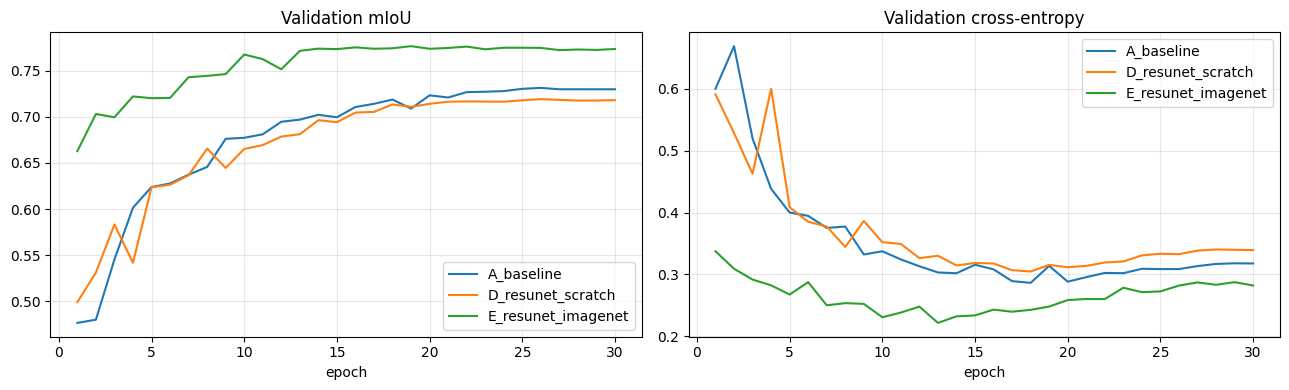

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in RESULTS.values():
    ep = [h['epoch'] for h in r['hist']]
    ax[0].plot(ep, [h['val_miou'] for h in r['hist']], label=r['name'])
    ax[1].plot(ep, [h['val_ce'] for h in r['hist']], label=r['name'])
ax[0].set(title="Validation mIoU", xlabel="epoch"); ax[1].set(title="Validation cross-entropy", xlabel="epoch")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{OUT}/m3_curves.png', dpi=150); plt.show()

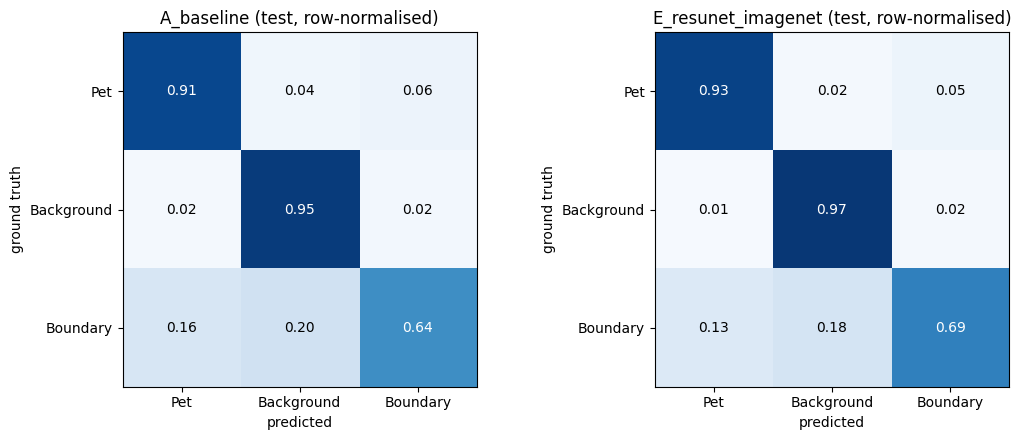

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, n in zip(ax, (BASE, BEST)):
    cm = RESULTS[n]['test']['cm']; cmn = cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    a.set(title=f"{n} (test, row-normalised)", xlabel="predicted", ylabel="ground truth",
          xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES)
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="w" if cmn[i, j] > .5 else "k")
plt.tight_layout(); plt.savefig(f'{OUT}/m3_confusion_matrices.png', dpi=150); plt.show()

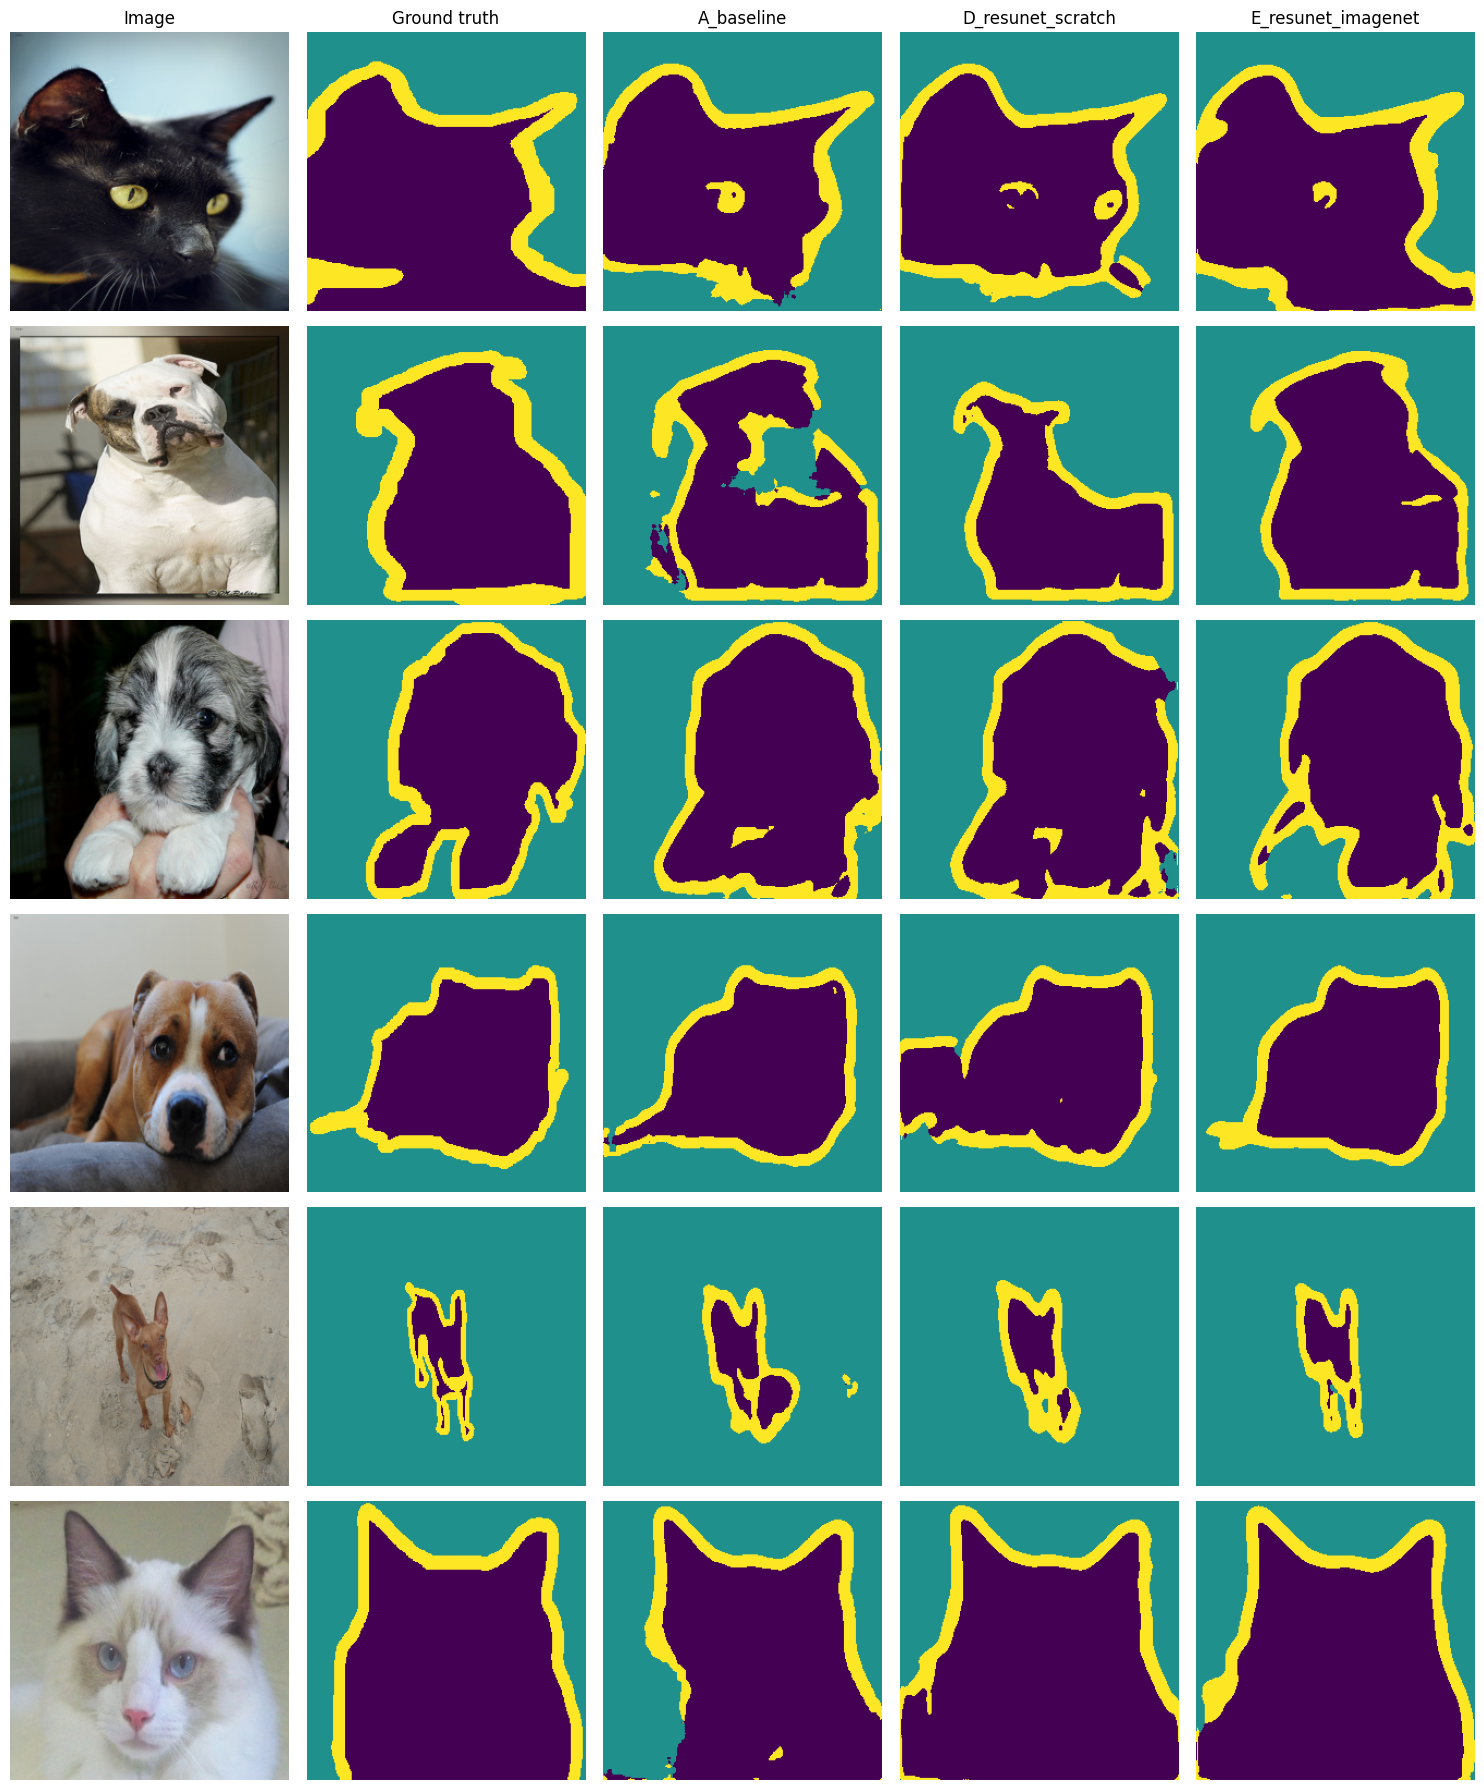

In [15]:
# same 6 test images as the Milestone 2 figure, so the two can be compared directly
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
sel = np.random.RandomState(0).choice(len(test_ds), 6, replace=False)
ds = PetSeg(test_ds, sel); cols = ["Image", "Ground truth"] + [n for n, _ in EXPERIMENTS]
fig, ax = plt.subplots(len(sel), len(cols), figsize=(3 * len(cols), 3 * len(sel)))
for r, (x, y) in enumerate(ds):
    preds = []
    for n, _ in EXPERIMENTS:
        m = RESULTS[n]['model'].eval()
        with torch.no_grad(): preds.append(m(x[None].to(device)).argmax(1)[0].cpu())
    for c, im in enumerate([(x * std + mean).permute(1, 2, 0).clamp(0, 1), y] + preds):
        ax[r, c].imshow(im, **({} if c == 0 else dict(vmin=0, vmax=2, cmap="viridis"))); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(cols[c])
plt.tight_layout(); plt.savefig(f'{OUT}/m3_predictions.png', dpi=120); plt.show()

## Is the improvement real? Per-image analysis on the test set

Every test image gets its own mIoU for the baseline and the improved model (same images, so the comparison is paired).
The bootstrap confidence interval shows how much the average gain could change with a different sample of test images.
It does **not** cover training randomness (one seed per run).

mean per-image mIoU: A_baseline 0.7373 | E_resunet_imagenet 0.7791 | gain +0.0418 (95% bootstrap CI +0.0395 .. +0.0442)
E_resunet_imagenet is better on 76.6% of test images, worse on 23.4%
Cat  (1183 images): A_baseline 0.7337 -> E_resunet_imagenet 0.7830 (+0.0493)
Dog  (2486 images): A_baseline 0.7390 -> E_resunet_imagenet 0.7772 (+0.0382)
hardest 10% of test images (by the average mIoU of both models): A_baseline 0.5192 -> E_resunet_imagenet 0.5800 (+0.0608)


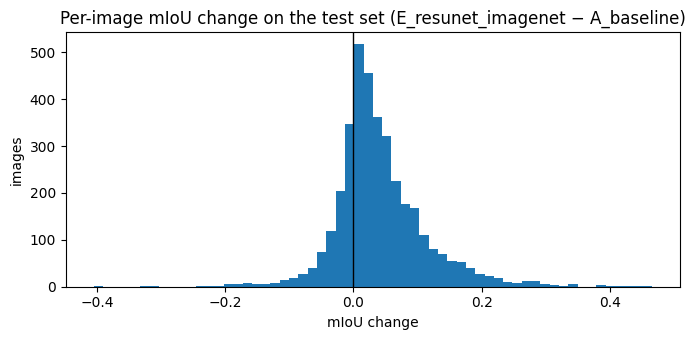

In [16]:
te_dl = loader(test_ds, range(len(test_ds)), False)
a, e = per_image_miou(RESULTS[BASE]['model'], te_dl), per_image_miou(RESULTS[BEST]['model'], te_dl)
d = e - a
rng = np.random.RandomState(0)
boot = np.array([d[rng.randint(0, len(d), len(d))].mean() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"mean per-image mIoU: {BASE} {a.mean():.4f} | {BEST} {e.mean():.4f} | gain {d.mean():+.4f} (95% bootstrap CI {lo:+.4f} .. {hi:+.4f})")
print(f"{BEST} is better on {(d > 0).mean():.1%} of test images, worse on {(d < 0).mean():.1%}")
species = np.array(test_ds._bin_labels)
for s, name in enumerate(["Cat", "Dog"]):
    k = species == s
    print(f"{name:<4} ({k.sum()} images): {BASE} {a[k].mean():.4f} -> {BEST} {e[k].mean():.4f} ({d[k].mean():+.4f})")
avg = (a + e) / 2   # rank difficulty by BOTH models; ranking by A alone would favour E (regression to the mean)
hard = avg < np.percentile(avg, 10)
print(f"hardest 10% of test images (by the average mIoU of both models): {BASE} {a[hard].mean():.4f} -> {BEST} {e[hard].mean():.4f} ({d[hard].mean():+.4f})")

plt.figure(figsize=(7, 3.5))
plt.hist(d, bins=60, color="tab:blue"); plt.axvline(0, color="k", lw=1)
plt.title(f"Per-image mIoU change on the test set ({BEST} − {BASE})"); plt.xlabel("mIoU change"); plt.ylabel("images")
plt.tight_layout(); plt.savefig(f'{OUT}/m3_per_image_gain.png', dpi=150); plt.show()

## Demo: segment new photos with the improved model

No training: loads the saved `E_resunet_imagenet` checkpoint. Put your own `.jpg` / `.png` photos in
`MyDrive/Pet-Image-Segmentation-CV/demo/` and run the cell. If the folder is empty, three random test images are used.
The prediction is made at 256×256 and resized back to the photo's own resolution.

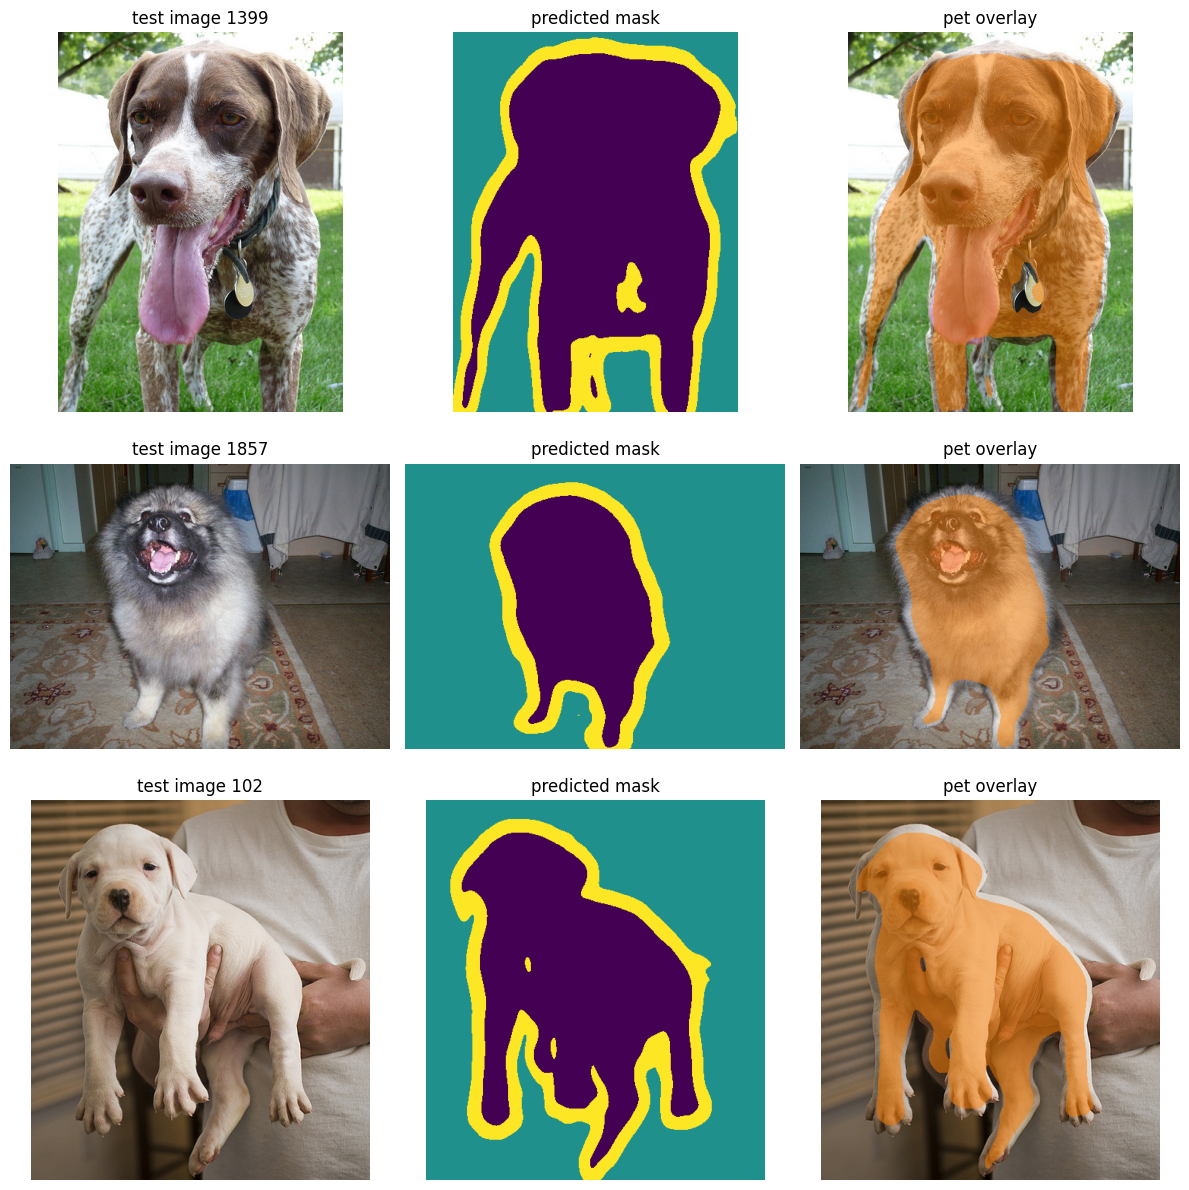

In [17]:
from PIL import Image
DEMO_DIR = f'{ROOT}/demo'; os.makedirs(DEMO_DIR, exist_ok=True)
demo_model = build("resunet").to(device)                     # same architecture as E; weights come from the checkpoint
demo_model.load_state_dict(torch.load(f'{OUT}/{BEST}.pt', map_location=device)); demo_model.eval()

@torch.no_grad()
def segment(img):   # PIL image -> label map at the photo's resolution (0 pet, 1 background, 2 boundary)
    S = CFG['img_size']
    x = TF(v2.Resize((S, S), antialias=True)(v2.ToImage()(img.convert('RGB'))))[None].to(device)
    logits = F.interpolate(demo_model(x), size=img.size[::-1], mode='bilinear', align_corners=False)
    return logits.argmax(1)[0].cpu().numpy()

files = sorted(p for p in os.listdir(DEMO_DIR) if p.lower().endswith(('.jpg', '.jpeg', '.png')))
imgs = [(p, Image.open(f'{DEMO_DIR}/{p}')) for p in files] or \
       [(f'test image {i}', test_ds[i][0]) for i in np.random.RandomState(1).choice(len(test_ds), 3, replace=False)]
fig, ax = plt.subplots(len(imgs), 3, figsize=(12, 4 * len(imgs)), squeeze=False)
for r, (name, img) in enumerate(imgs):
    img = img.convert('RGB'); m = segment(img)
    over = np.asarray(img, dtype=float) / 255; pet = m == 0
    over[pet] = 0.5 * over[pet] + 0.5 * np.array([1.0, 0.5, 0.0])   # orange tint on pet pixels
    for c, (im, title) in enumerate([(img, name), (m, 'predicted mask'), (over, 'pet overlay')]):
        ax[r, c].imshow(im, **(dict(vmin=0, vmax=2, cmap='viridis') if c == 1 else {})); ax[r, c].set_title(title); ax[r, c].axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/m3_demo.png', dpi=110); plt.show()

## Analysis (not the improvement): what happens with a longer training budget?

Two observations from the 30-epoch runs motivate this section:
- In Milestone 2 the augmented run **C** (augmentation + Dice) was still improving at epoch 30. Hypothesis: augmentation needs more training.
- In this milestone the from-scratch ablation **D** was still improving at epoch 30, so the D-vs-E gap may overstate the benefit of pretraining.

A, C, D and E are retrained with a **60-epoch budget and early stopping** (stop when validation mIoU has not improved for 10 epochs).
Everything else is unchanged. The cosine learning-rate schedule spans the 60 epochs.

**This is analysis only.** A longer budget is a hyper-parameter change, and C uses augmentation and Dice loss, so none of these runs
count as the Milestone 3 improvement. The official comparison stays A vs E at 30 epochs, the Milestone 2 budget.
The summary cell at the end reads the saved result files, so it also works in a fresh session.

In [18]:
LONG = dict(epochs=60, patience=10)   # 60-epoch budget; stop after 10 epochs without a new best validation mIoU
LONG_RESULTS = {}

# Milestone 2 augmentation and Dice loss, used only to re-run C (identical settings to Milestone 2)
AUG = v2.Compose([v2.RandomResizedCrop(CFG['img_size'], scale=(0.5, 1.0), antialias=True), v2.RandomHorizontalFlip(),
                  v2.RandomRotation(15, fill={tv_tensors.Image: 0, tv_tensors.Mask: 1}),   # padding labelled background
                  v2.ColorJitter(0.3, 0.3, 0.3, 0.05)])

class PetSegAug(PetSeg):
    def __getitem__(self, i):
        img, m = TF(*AUG(*self.data[self.idx[i]]))
        return img, m.as_subclass(torch.Tensor).long()

def dice_loss(logits, y, eps=1.0):   # soft Dice, averaged over the 3 classes
    p = logits.softmax(1); oh = F.one_hot(y, 3).permute(0, 3, 1, 2).float()
    inter = (p * oh).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

def run_long(name, arch, augment=False, loss_kind="ce"):
    # same training loop as run_experiment, plus the longer budget, early stopping and (for C) augmentation + Dice
    epochs, patience = LONG['epochs'], LONG['patience']
    set_seed(CFG['seed'])
    tr_dl = DataLoader((PetSegAug if augment else PetSeg)(trainval_ds, train_idx), batch_size=CFG['batch_size'], shuffle=True,
                       drop_last=True, num_workers=CFG['num_workers'], pin_memory=device.type == 'cuda')
    va_dl = loader(trainval_ds, val_idx, False)
    te_dl = loader(test_ds, range(len(test_ds)), False)
    model = build(arch).to(device)
    ckpt, js = f'{OUT}/{name}.pt', f'{OUT}/{name}.json'
    meta = dict(cfg={**CFG, 'epochs': epochs}, augment=augment, loss=loss_kind, arch=arch, patience=patience)
    if os.path.exists(ckpt) and os.path.exists(js):
        saved = json.load(open(js))
        if {k: saved.get(k) for k in meta} == meta:   # finished earlier: reload, don't retrain
            model.load_state_dict(torch.load(ckpt, map_location=device))
            print(f"[{name}] already trained (best epoch {saved['best_epoch']} of {len(saved['hist'])}) -> reloaded from {OUT}")
            return dict(name=name, model=model, hist=saved['hist'], best_epoch=saved['best_epoch'],
                        val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == 'cuda')
    hist, best, t0 = [], (-1, 0), time.time()
    for ep in range(1, epochs + 1):
        model.train(); tl = 0.0
        for x, y in tr_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == 'cuda'):
                out = model(x)
            out = out.float(); loss = F.cross_entropy(out, y)
            if loss_kind == "ce_dice":
                loss = loss + dice_loss(out, y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item()
        sched.step()
        v = evaluate(model, va_dl)
        hist.append(dict(epoch=ep, train_loss=tl / len(tr_dl), val_ce=v['ce'], val_miou=v['miou'], val_mdice=v['mdice']))
        if v['miou'] > best[0]:
            best = (v['miou'], ep); torch.save(model.state_dict(), ckpt)
        print(f"[{name}] ep {ep:02d} train {hist[-1]['train_loss']:.4f} | val CE {v['ce']:.4f} mIoU {v['miou']:.4f} mDice {v['mdice']:.4f} | {(time.time() - t0) / 60:.1f} min")
        if ep - best[1] >= patience:
            print(f"[{name}] early stop: no validation mIoU gain for {patience} epochs (best epoch {best[1]})"); break
    model.load_state_dict(torch.load(ckpt, map_location=device))
    res = dict(name=name, model=model, hist=hist, best_epoch=best[1], val=evaluate(model, va_dl), test=evaluate(model, te_dl))
    json.dump(dict(**meta, hist=hist, best_epoch=best[1], minutes=(time.time() - t0) / 60,
                   val_miou=res['val']['miou'], test_miou=res['test']['miou']), open(js, 'w'), indent=1)   # written last = "run finished"
    return res

One cell per run. Rough cost on the Colab GPU if early stopping never triggers: about 50 min each for A and C, about 35 min each for D and E.

In [19]:
LONG_RESULTS['A_e60'] = run_long('A_e60', 'unet')

[A_e60] already trained (best epoch 31 of 41) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [20]:
LONG_RESULTS['C_e60'] = run_long('C_e60', 'unet', augment=True, loss_kind='ce_dice')

[C_e60] already trained (best epoch 59 of 60) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [21]:
LONG_RESULTS['D_e60'] = run_long('D_e60', 'resunet')

[D_e60] already trained (best epoch 34 of 44) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


In [22]:
LONG_RESULTS['E_e60'] = run_long('E_e60', 'resunet_imagenet')

[E_e60] already trained (best epoch 18 of 28) -> reloaded from /content/drive/MyDrive/Pet-Image-Segmentation-CV/outputs


run                    budget  ran  best ep  val mIoU  test mIoU
A baseline                 30   30       26    0.7314     0.7437
A baseline                 60   41       31    0.7355     0.7462
C aug + Dice (M2)          30   30       28    0.7193     0.7374
C aug + Dice (M2)          60   60       59    0.7536     0.7708
D ResNet-34 scratch        30   30       26    0.7192     0.7289
D ResNet-34 scratch        60   44       34    0.7263     0.7321
E ResNet-34 ImageNet       30   30       19    0.7766     0.7853
E ResNet-34 ImageNet       60   28       18    0.7788     0.7897


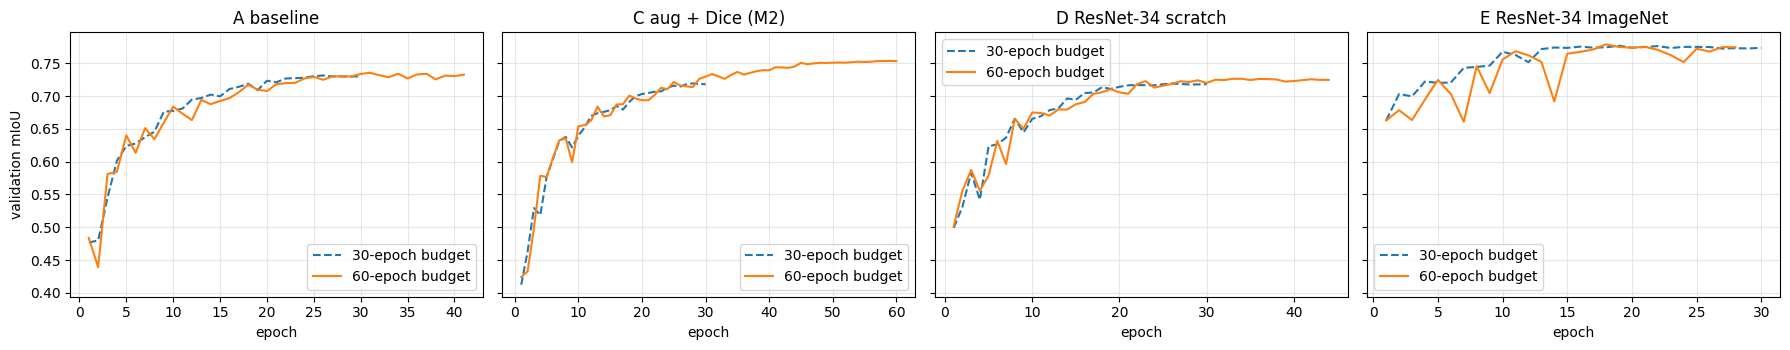

In [23]:
# 30-epoch vs 60-epoch budget, read from the saved result files (dashed = 30 epochs, solid = 60 epochs + early stopping)
PAIRS = [("A baseline", "A_baseline", "A_e60"), ("C aug + Dice (M2)", "C_aug_dice", "C_e60"),
         ("D ResNet-34 scratch", "D_resunet_scratch", "D_e60"), ("E ResNet-34 ImageNet", "E_resunet_imagenet", "E_e60")]
print(f"{'run':<22}{'budget':>7}{'ran':>5}{'best ep':>9}{'val mIoU':>10}{'test mIoU':>11}")
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for axi, (label, short, long_) in zip(ax, PAIRS):
    for n, style in ((short, '--'), (long_, '-')):
        p = f'{OUT}/{n}.json'
        if not os.path.exists(p):
            print(f"{label:<22}{n}: not run yet"); continue
        s = json.load(open(p)); h = s['hist']
        print(f"{label:<22}{s['cfg']['epochs']:>7}{len(h):>5}{s['best_epoch']:>9}{s['val_miou']:>10.4f}{s['test_miou']:>11.4f}")
        axi.plot([x['epoch'] for x in h], [x['val_miou'] for x in h], style, label=f"{s['cfg']['epochs']}-epoch budget")
    axi.set(title=label, xlabel="epoch"); axi.grid(alpha=.3); axi.legend()
ax[0].set_ylabel("validation mIoU")
plt.tight_layout(); plt.savefig(f'{OUT}/m3_long_curves.png', dpi=150); plt.show()